In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
master=pd.read_csv("C:\\Users\\HP\\Downloads\\Customer_Master_data.csv")
trans=pd.read_csv("C:\\Users\\HP\\Downloads\\customer_Transactions.csv")

## Data check ##

In [3]:
master.head()

,Customer_ID,Customer_Name,Gender,Age,City,State,Phone,Email,Join_Date
0,101,Amit Kumar,Male,28,Bhubaneswar,Odisha,9876543210,amit@example.com,2025-01-15
1,102,Priya Das,Female,25,Cuttack,Odisha,9876501234,priya@example.com,2025-02-10
2,103,Rahul Panda,Male,31,Puri,Odisha,9123456780,rahul@example.com,2025-03-05
3,104,Sneha Sahoo,Female,27,Rourkela,Odisha,9988776655,sneha@example.com,2025-04-12
4,105,Rakesh Nayak,Male,35,Balasore,Odisha,9090909090,rakesh@example.com,2025-05-20


In [4]:
trans.head()

,Transaction_ID,Customer_ID,Transaction_Date,Product,Quantity,Amount,Payment_Mode
0,1001,101,2025-06-01,Laptop,1,55000,UPI
1,1002,102,2025-06-02,Mouse,2,1200,Card
2,1003,103,2025-06-03,Keyboard,1,1800,Cash
3,1004,104,2025-06-04,Monitor,1,14500,UPI
4,1005,105,2025-06-05,Headphones,2,3200,Card


In [5]:
master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Customer_ID    5 non-null      int64 
 1   Customer_Name  5 non-null      object
 2   Gender         5 non-null      object
 3   Age            5 non-null      int64 
 4   City           5 non-null      object
 5   State          5 non-null      object
 6   Phone          5 non-null      int64 
 7   Email          5 non-null      object
 8   Join_Date      5 non-null      object
dtypes: int64(3), object(6)
memory usage: 492.0+ bytes


In [6]:
trans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction_ID    6 non-null      int64 
 1   Customer_ID       6 non-null      int64 
 2   Transaction_Date  6 non-null      object
 3   Product           6 non-null      object
 4   Quantity          6 non-null      int64 
 5   Amount            6 non-null      int64 
 6   Payment_Mode      6 non-null      object
dtypes: int64(4), object(3)
memory usage: 468.0+ bytes


## Data cleaning ##

In [7]:
master.isnull().sum()

Customer_ID      0
Customer_Name    0
Gender           0
Age              0
City             0
State            0
Phone            0
Email            0
Join_Date        0
dtype: int64

In [8]:
trans.isnull().sum()

Transaction_ID      0
Customer_ID         0
Transaction_Date    0
Product             0
Quantity            0
Amount              0
Payment_Mode        0
dtype: int64

In [9]:
master.duplicated().sum()

np.int64(0)

In [10]:
trans.duplicated().sum()

np.int64(0)

## Date conversion ##

In [11]:
master["Join_Date"] = pd.to_datetime(master["Join_Date"], dayfirst=True)

trans["Transaction_Date"] = pd.to_datetime(trans["Transaction_Date"], dayfirst=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_17456\3898739132.py:1: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  master["Join_Date"] = pd.to_datetime(master["Join_Date"], dayfirst=True)


In [12]:
master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Customer_ID    5 non-null      int64         
 1   Customer_Name  5 non-null      object        
 2   Gender         5 non-null      object        
 3   Age            5 non-null      int64         
 4   City           5 non-null      object        
 5   State          5 non-null      object        
 6   Phone          5 non-null      int64         
 7   Email          5 non-null      object        
 8   Join_Date      5 non-null      datetime64[ns]
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 492.0+ bytes


In [13]:
trans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    6 non-null      int64         
 1   Customer_ID       6 non-null      int64         
 2   Transaction_Date  6 non-null      datetime64[ns]
 3   Product           6 non-null      object        
 4   Quantity          6 non-null      int64         
 5   Amount            6 non-null      int64         
 6   Payment_Mode      6 non-null      object        
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 468.0+ bytes


## Merge ##

In [14]:
df = pd.merge(master, trans, on="Customer_ID", how="inner")

df.head()

,Customer_ID,Customer_Name,Gender,Age,City,State,Phone,Email,Join_Date,Transaction_ID,Transaction_Date,Product,Quantity,Amount,Payment_Mode
0,101,Amit Kumar,Male,28,Bhubaneswar,Odisha,9876543210,amit@example.com,2025-01-15,1001,2025-01-06,Laptop,1,55000,UPI
1,101,Amit Kumar,Male,28,Bhubaneswar,Odisha,9876543210,amit@example.com,2025-01-15,1006,2025-06-06,USB Drive,3,1800,Cash
2,102,Priya Das,Female,25,Cuttack,Odisha,9876501234,priya@example.com,2025-02-10,1002,2025-02-06,Mouse,2,1200,Card
3,103,Rahul Panda,Male,31,Puri,Odisha,9123456780,rahul@example.com,2025-03-05,1003,2025-03-06,Keyboard,1,1800,Cash
4,104,Sneha Sahoo,Female,27,Rourkela,Odisha,9988776655,sneha@example.com,2025-04-12,1004,2025-04-06,Monitor,1,14500,UPI


## Reference Date ##

In [15]:
reference_date = df["Transaction_Date"].max() + pd.Timedelta(days=1)
print(reference_date)

2025-06-07 00:00:00


## RFM Table ##

In [16]:
rfm = df.groupby("Customer_ID").agg({
    "Transaction_Date": lambda x: (reference_date - x.max()).days,
    "Transaction_ID": "count",
    "Amount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm = rfm.reset_index()

rfm.head()

,Customer_ID,Recency,Frequency,Monetary
0,101,1,2,56800
1,102,121,1,1200
2,103,93,1,1800
3,104,62,1,14500
4,105,32,1,3200


In [17]:
rfm.head()

,Customer_ID,Recency,Frequency,Monetary
0,101,1,2,56800
1,102,121,1,1200
2,103,93,1,1800
3,104,62,1,14500
4,105,32,1,3200


## R score ##

In [18]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5,4,3,2,1]
)

## F Score ##

In [19]:
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1,2,3,4,5]
)

## M Score ##

In [20]:
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1,2,3,4,5]
)

In [21]:
rfm.head()

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,101,1,2,56800,5,5,5
1,102,121,1,1200,1,1,1
2,103,93,1,1800,2,2,2
3,104,62,1,14500,3,3,4
4,105,32,1,3200,4,4,3


## RFM Score Combine ##

In [22]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm.head()

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,101,1,2,56800,5,5,5,555
1,102,121,1,1200,1,1,1,111
2,103,93,1,1800,2,2,2,222
3,104,62,1,14500,3,3,4,334
4,105,32,1,3200,4,4,3,443


## Segment Label ##

In [23]:
conditions = [
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 4),
    (rfm["F_Score"] >= 4),
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 2),
    (rfm["R_Score"] <= 2) & (rfm["F_Score"] >= 3),
    (rfm["R_Score"] == 1) & (rfm["F_Score"] <= 2)
]

choices = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalist",
    "At Risk",
    "Lost"
]

rfm["Segment"] = np.select(conditions, choices, default="Others")

rfm.head()

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,101,1,2,56800,5,5,5,555,Loyal Customers
1,102,121,1,1200,1,1,1,111,Lost
2,103,93,1,1800,2,2,2,222,Potential Loyalist
3,104,62,1,14500,3,3,4,334,Potential Loyalist
4,105,32,1,3200,4,4,3,443,Loyal Customers


## Bar Chart ##

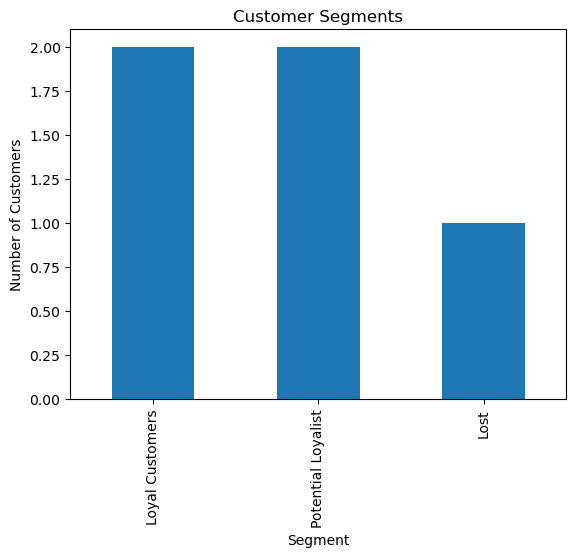

In [24]:
rfm["Segment"].value_counts().plot(kind="bar")
plt.title("Customer Segments")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.show()

## pie chart ##

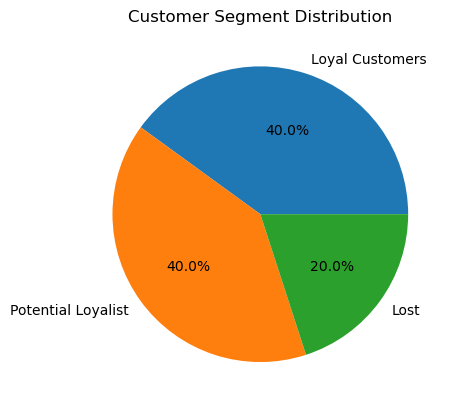

In [25]:
rfm["Segment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Customer Segment Distribution")
plt.ylabel("")
plt.show()

### Business Insights

1. Champions are the most valuable customers and should receive loyalty rewards.
2. Loyal customers should be targeted with special offers and discounts.
3. At-risk customers need re-engagement campaigns.
4. Lost customers can be approached with promotional offers.
5. RFM analysis helps identify customer purchasing behavior and supports better marketing decisions.

## Revenue Contribution by Segment ##

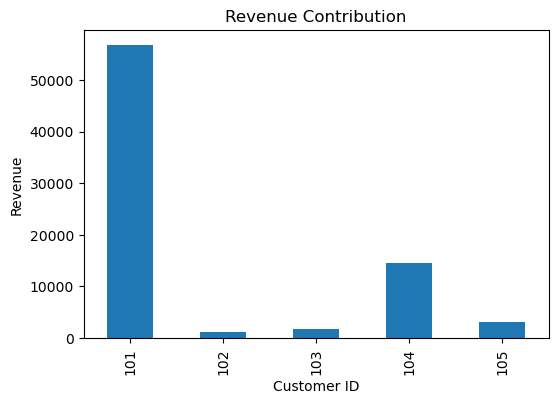

In [26]:
segment_revenue = df.groupby("Customer_ID")["Amount"].sum()

plt.figure(figsize=(6,4))
segment_revenue.plot(kind="bar")
plt.title("Revenue Contribution")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")
plt.show()

## Recency vs Monetary scatter plot ##

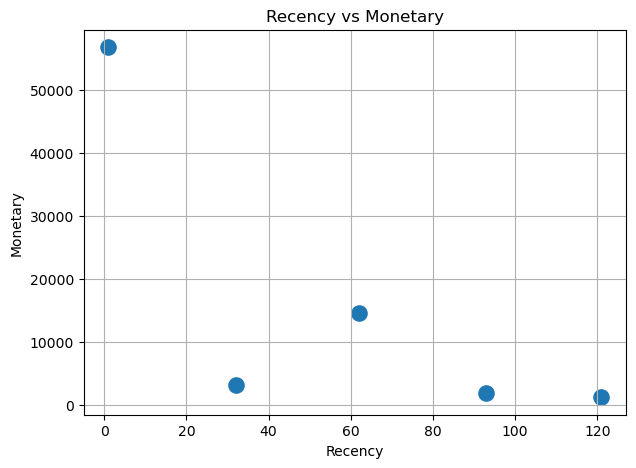

In [27]:
plt.figure(figsize=(7,5))

plt.scatter(
    rfm["Recency"],
    rfm["Monetary"],
    s=120
)

plt.title("Recency vs Monetary")
plt.xlabel("Recency")
plt.ylabel("Monetary")

plt.grid(True)

plt.show()

## pareto analysis (80/20) Rule ##

In [28]:
pareto = rfm.sort_values(
    by="Monetary",
    ascending=False
)

pareto["Cum_Revenue"] = pareto["Monetary"].cumsum()

pareto["Cum_Percentage"] = (
    pareto["Cum_Revenue"] /
    pareto["Monetary"].sum()
) * 100

pareto

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cum_Revenue,Cum_Percentage
0,101,1,2,56800,5,5,5,555,Loyal Customers,56800,73.290323
3,104,62,1,14500,3,3,4,334,Potential Loyalist,71300,92.000000
4,105,32,1,3200,4,4,3,443,Loyal Customers,74500,96.129032
2,103,93,1,1800,2,2,2,222,Potential Loyalist,76300,98.451613
1,102,121,1,1200,1,1,1,111,Lost,77500,100.000000


**charts**

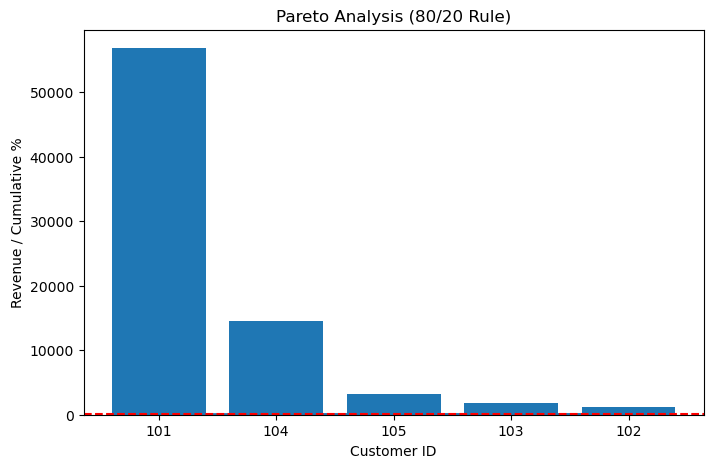

In [29]:
plt.figure(figsize=(8,5))

plt.bar(
    pareto["Customer_ID"].astype(str),
    pareto["Monetary"]
)

plt.plot(
    pareto["Customer_ID"].astype(str),
    pareto["Cum_Percentage"],
    marker="o"
)

plt.axhline(
    y=80,
    color="red",
    linestyle="--"
)

plt.title("Pareto Analysis (80/20 Rule)")
plt.xlabel("Customer ID")
plt.ylabel("Revenue / Cumulative %")

plt.show()

## Segment summary Table ##

In [30]:
summary = rfm.groupby("Segment").agg(
    Customers=("Customer_ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Total_Monetary=("Monetary", "sum")
)

summary

,Customers,Avg_Recency,Avg_Frequency,Total_Monetary
Segment,,,,
Lost,1,121.0,1.0,1200
Loyal Customers,2,16.5,1.5,60000
Potential Loyalist,2,77.5,1.0,16300


## save final RFM result ##

In [31]:
rfm.to_csv("RFM_Final_Result.csv", index=False)

print("RFM_Final_Result.csv saved successfully")

RFM_Final_Result.csv saved successfully


## Conclusion

This project analyzed customer transaction data using Python and Pandas.

- Customer data was cleaned and validated.
- RFM (Recency, Frequency, Monetary) metrics were calculated.
- Customers were segmented based on RFM scores.
- Visualizations were created to understand customer behavior.
- Pareto Analysis identified the highest revenue-contributing customers.
- The analysis helps businesses improve customer retention, marketing strategies, and decision-making.